# 04 · EMT-TF Expression — Dong 2020 Neuroblastoma

The EMT-TF readout is **unconditional** (produced regardless of gate outcome; here the last
notebook, non-branching GO chain). Score a wide mesenchymal panel — Snail/Zeb/Twist **plus** the
FOXC and PRRX families (VIM is a marker, not a TF, and is excluded) — gated on **detectable
expression**, and pick the most informative early(root) and late(terminus) factors by their
pseudotime trend. Show them as a **categorical overlay of thresholded expressers** on a grey
manifold (the reference deliverable style), not a continuous colormap.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig  = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)
print('dataset:', name)

dataset: Dong2020_Neuroendocrine


### Two-panel data limitation — recover the full EMT-TF panel from Group2
Dong 2020 is captured in two groups with **different gene panels**: Group1 (10 tumours) ships a
curated 12 595-gene panel that omits SNAI2, TWIST1/2, **FOXC1/2 and PRRX1/2**; Group2 (3 tumours)
ships a near-whole-transcriptome 33 490-gene panel carrying all ten. The joint manifold is built
on the shared panel (correct — see 01), on which only SNAI1/ZEB1/ZEB2 are measured. To honour the
binding requirement to score the **FOXC and PRRX families**, the EMT-TF readout is evaluated on the
**Group2 cells** (24 870, whole-transcriptome), positioned on the joint manifold with their joint
pseudotime. Group2 expression is normalised identically (`normalize_total`+`log1p`). This is a
3-tumour subset — the stated limitation of a two-panel dataset.

In [3]:
import anndata as ad
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
g2 = load_CCCA_adata(os.path.join(pth, 'data','unzip','CCCA','Data_'+name,'Group2'), verbose=False)
g2 = g2[g2.obs.celltype=='Malignant'].copy()
sc.pp.normalize_total(g2); sc.pp.log1p(g2)          # identical normalisation
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
panel = [g for g in panel if g in g2.var_names]
# align Group2 cells to their position/pseudotime on the joint manifold
common = [c for c in adata.obs_names if c in set(g2.obs_names)]
sub = adata[common].copy()
g2 = g2[common, panel].copy()
Xe = g2.X.toarray() if hasattr(g2.X,'toarray') else np.asarray(g2.X)
for j,gname in enumerate(panel): sub.obs['EMT_'+gname] = Xe[:,j]
t = sub.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print(f'EMT-TF panel scored on {sub.n_obs} Group2 cells (whole-transcriptome); panel = {panel}')

EMT-TF panel scored on 24870 Group2 cells (whole-transcriptome); panel = ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'TWIST1', 'TWIST2', 'FOXC1', 'FOXC2', 'PRRX1', 'PRRX2']


### Score EMT-TF panel, gated on detection
For each factor report detection fraction, mean expression in the early/late pseudotime terciles,
and the Spearman trend vs pseudotime. Keep only factors above a 3% detection floor (10x dropout),
then take the most-detected/informative early and late factors (VIM excluded — it is a marker,
not a transcription factor).

In [4]:
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
rows = []
for gname in panel:
    x = sub.obs['EMT_'+gname].values; rho,_ = spearmanr(tn, x)
    rows.append((gname, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\ndetected (>3%): {ok.TF.tolist()}')
print(f'derived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 PRRX2      0.447       0.296      0.282    -0.015    EARLY(root)
  ZEB1      0.369       0.232      0.210    -0.011    EARLY(root)
TWIST1      0.879       0.799      0.801    -0.007 LATE(terminus)
TWIST2      0.000       0.000      0.000    -0.005 LATE(terminus)
 FOXC2      0.001       0.001      0.000    -0.003    EARLY(root)
 SNAI1      0.012       0.006      0.005     0.011    EARLY(root)
 SNAI2      0.005       0.002      0.002     0.012 LATE(terminus)
 PRRX1      0.002       0.000      0.001     0.018 LATE(terminus)
  ZEB2      0.255       0.122      0.153     0.082 LATE(terminus)
 FOXC1      0.302       0.139      0.250     0.147 LATE(terminus)

detected (>3%): ['PRRX2', 'ZEB1', 'TWIST1', 'ZEB2', 'FOXC1']
derived pair: PRRX2 (early/root) <-> FOXC1 (late/terminus)


### EMT-TF overlay figure (deliverable)
Two factors overlaid as **thresholded expressers** (upper quartile among expressing cells) in
distinct colours on the grey joint manifold, house `(3.5,1.5)` aspect — the reference
categorical-overlay style. The full malignant manifold (all 47 384 cells) is the grey background;
Group2 expressers are coloured. Report the pseudotime separation of the shown cells.

overlay thresholds (upper quartile among expressers): {'PRRX2': 0.805, 'FOXC1': 0.869} | cells shown: {'PRRX2': 2779, 'FOXC1': 1880}
PRRX2: 44.7% expressing; 2779 shown; mean pt of shown = 0.42 (all 0.46)
FOXC1: 30.2% expressing; 1880 shown; mean pt of shown = 0.51 (all 0.46)
shown-cell pseudotime separation = 0.09
saved expression.pdf


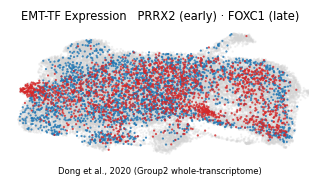

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g): return sub.obs['EMT_'+g].values
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos,0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf,late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf,late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=8, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = sub[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=8, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Dong et al., 2020 (Group2 whole-transcriptome)', ha='center', transform=ax.transAxes, size=5.5)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown; mean pt of shown = {tn[m].mean():.2f} (all {tn.mean():.2f})')
print(f'shown-cell pseudotime separation = {abs(tn[sel[late_tf]].mean()-tn[sel[early_tf]].mean()):.2f}')
print('saved expression.pdf')